# Notebook 3: Measurement Experiments

*Quantum for Energy Academy | Lecture 5: Your First Quantum Program*  
*Prof. Lilia Tightiz, Department of Computer Engineering, Sejong University*

**Goals of this notebook**

1. Separate exact probabilities from sampled frequencies.
2. Compare 100, 1,024 and 10,000 shots.
3. See why counts such as 515 and 509 are normal for 1,024 shots.
4. Recognize a silent mistake: a forgotten measurement.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector

SEED = 42
OUTPUT_DIR = Path("..") / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)


def run_counts(circuit, shots, seed=SEED):
    """Run a circuit on the local sampler and return its counts."""
    return StatevectorSampler(seed=seed).run([circuit], shots=shots).result()[0].data.c.get_counts()

## 1. Exact probabilities vs sampled frequencies

* **Exact:** the statevector gives $P(0) = P(1) = 0.5$. No randomness.
* **Sampled:** each shot is a random draw. The frequency $f_0 = \text{count}_0 / N$ changes from run to run.

The typical size of the deviation is the standard deviation of $f_0$:

$$\sigma = \sqrt{\frac{p(1-p)}{N}} = \frac{0.5}{\sqrt{N}} \quad (p = 0.5).$$

In [2]:
exact = Statevector(qc.remove_final_measurements(inplace=False)).probabilities()
p0 = float(exact[0])
print("Exact P(0) =", round(p0, 12))

print()
print(" Shots | Count 0 | Count 1 | Freq 0 | |Freq 0 - 0.5| | sigma")
rows = []
for shots in (100, 1024, 10000):
    counts = run_counts(qc, shots)
    f0 = counts.get("0", 0) / shots
    sigma = math.sqrt(p0 * (1 - p0) / shots)
    rows.append((shots, f0, abs(f0 - p0), sigma))
    print(f"{shots:6d} | {counts.get('0', 0):7d} | {counts.get('1', 0):7d} | {f0:.4f} |"
          f"     {abs(f0 - p0):.4f}     | {sigma:.4f}")

Exact P(0) = 0.5

 Shots | Count 0 | Count 1 | Freq 0 | |Freq 0 - 0.5| | sigma
   100 |      53 |      47 | 0.5300 |     0.0300     | 0.0500
  1024 |     515 |     509 | 0.5029 |     0.0029     | 0.0156
 10000 |    5015 |    4985 | 0.5015 |     0.0015     | 0.0050


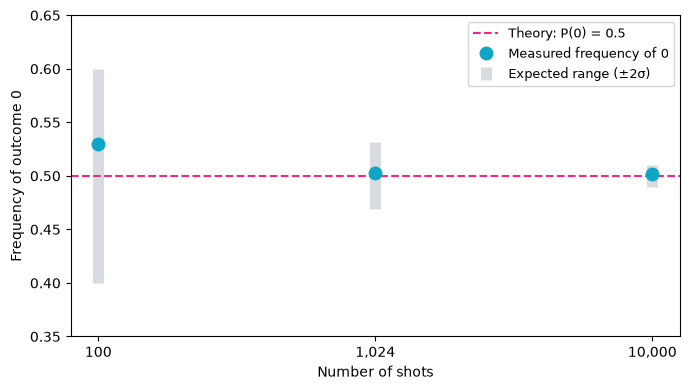

In [3]:
labels = [f"{shots:,}" for shots, *_ in rows]
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(0.5, color="#F72585", linestyle="--", label="Theory: P(0) = 0.5")
ax.errorbar(x, [0.5] * len(rows), yerr=[2 * r[3] for r in rows], fmt="none",
            ecolor="#64748B", elinewidth=8, alpha=0.25, label="Expected range (±2σ)")
ax.plot(x, [r[1] for r in rows], "o", color="#0EA5C6", markersize=9, label="Measured frequency of 0")
ax.set_xticks(x, labels)
ax.set_ylim(0.35, 0.65)
ax.set_xlabel("Number of shots")
ax.set_ylabel("Frequency of outcome 0")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nb03_shots_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Same circuit, different seeds

The seed fixes the random numbers. A different seed gives a different, equally valid sample.

In [4]:
for seed in range(10):
    counts = run_counts(qc, 1024, seed=seed)
    print(f"seed {seed}: {counts.get('0', 0)} zeros, {counts.get('1', 0)} ones")

seed 0: 487 zeros, 537 ones
seed 1: 518 zeros, 506 ones
seed 2: 512 zeros, 512 ones
seed 3: 515 zeros, 509 ones
seed 4: 486 zeros, 538 ones
seed 5: 535 zeros, 489 ones
seed 6: 506 zeros, 518 ones
seed 7: 517 zeros, 507 ones
seed 8: 533 zeros, 491 ones
seed 9: 518 zeros, 506 ones


## 3. The spread follows the binomial distribution

For $N$ shots with $p = 0.5$, the count of zeros follows a binomial distribution with

$$\text{mean} = Np = 512, \qquad \text{standard deviation} = \sqrt{Np(1-p)} = 16 \quad (N = 1024).$$

About 95% of runs give a count between 480 and 544. The cell below repeats the experiment
500 times (500 seeds) and compares the spread with the binomial formula.

Mean count of 0 : 511.47 (theory 512)
Std of the count: 16.28 (theory 16)
Share within 480 to 544: 0.942 (theory about 0.95)


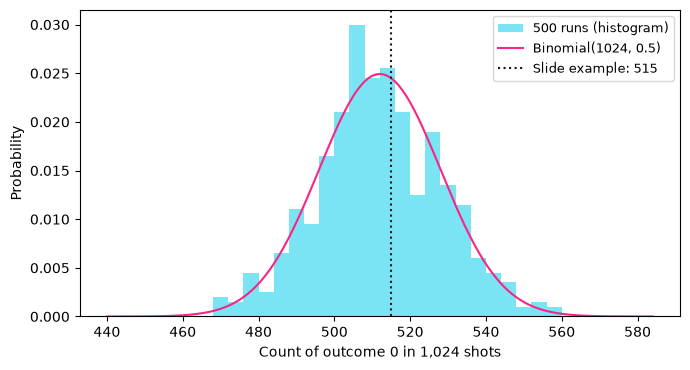

In [5]:
N = 1024
zeros = np.array([run_counts(qc, N, seed=s).get("0", 0) for s in range(500)])
print("Mean count of 0 :", zeros.mean().round(2), "(theory 512)")
print("Std of the count:", zeros.std(ddof=1).round(2), "(theory 16)")
print("Share within 480 to 544:", np.mean((zeros >= 480) & (zeros <= 544)).round(3), "(theory about 0.95)")

k = np.arange(440, 585)
pmf = np.array([math.comb(N, int(i)) / 2**N for i in k])  # exact integers, then one division
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(zeros, bins=np.arange(440, 586, 4), density=True, color="#22D3EE", alpha=0.6, label="500 runs (histogram)")
ax.plot(k, pmf, color="#F72585", label="Binomial(1024, 0.5)")
ax.axvline(515, color="#0F172A", linestyle=":", label="Slide example: 515")
ax.set_xlabel("Count of outcome 0 in 1,024 shots")
ax.set_ylabel("Probability")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. A silent mistake: the forgotten measurement

The circuit below has a classical bit, but no `measure` call.
The sampler still reports the classical bit. It was never written, so it is always 0.
No error appears. Always check the circuit diagram for the measurement box (**M**).

In [6]:
no_measure = QuantumCircuit(1, 1)
no_measure.h(0)  # no measure line here
print(no_measure.draw())
print("Counts:", run_counts(no_measure, 1024))

     ┌───┐
  q: ┤ H ├
     └───┘
c: 1/═════
          
Counts: {'0': 1024}


## 5. Simulator vs hardware

`StatevectorSampler` computes the exact state on your CPU and then draws random samples.
All the spread above comes from the **finite number of samples** only. A real quantum processor (QPU)
adds hardware errors on top: gate errors, readout errors and decoherence.
The statevector method also needs $2^n$ amplitudes for $n$ qubits, so it suits small circuits only.

## 6. Exercise 4

Use the table in section 1. For each number of shots, compute the absolute deviation
$|f_0 - 0.5|$ and compare it with $\sigma = 0.5/\sqrt{N}$.
Then change `SEED` in the first code cell and run all cells again.

Solutions: `../exercises/instructor_solutions.md`.